# NN_L1_boundary_hmeq

**Predicted probability of default on two HMEQ variables (debt-to-income, age of the oldest credit line): straight bands of logistic regression against the curved regions of an MLP 64-64, with test loans.**

Neural Networks and Deep Learning (NN), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L1/NN_L1_boundary_hmeq/NN_L1_boundary_hmeq.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 1 of *Neural Networks and Deep Learning*: the chart `boundary_hmeq` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

test AUC, logistic, two inputs = 0.744   [two.auc_logit]
test AUC, MLP 64-64, two inputs = 0.736   [two.auc_mlp]


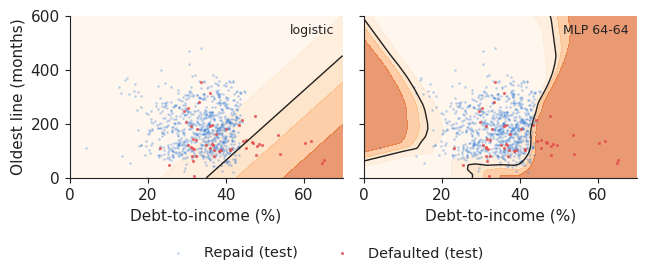

In [3]:
import xgboost as xgb            # import before torch (OpenMP runtimes on macOS)
import torch, torch.nn as nn
torch.set_num_threads(1)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import train_test_split, StratifiedKFold
SEED = 20261108

class MLP(nn.Module):
    def __init__(self, d, hidden=(64, 64), act='relu'):
        super().__init__()
        A = {'relu': nn.ReLU, 'tanh': nn.Tanh, 'sigmoid': nn.Sigmoid}[act]
        layers, k = [], d
        for h in hidden:
            layers += [nn.Linear(k, h), A()]; k = h
        layers.append(nn.Linear(k, 1)); self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def train_mlp(Xtr, ytr, Xva, yva, hidden=(64, 64), act='relu', lr=1e-3, epochs=300, bs=128, patience=25, seed=0):
    """Adam on mini-batches; keeps the weights of the best validation epoch"""
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = MLP(Xtr.shape[1], hidden, act); opt = torch.optim.Adam(m.parameters(), lr=lr); lf = nn.BCEWithLogitsLoss()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva, dtype=torch.float32).view(-1, 1)
    best, state, bad = np.inf, None, 0
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); lf(m(Xt[b]), yt[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(lf(m(Xv), yv))
        if vl < best - 1e-5:
            best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(state); m.eval()
    return m

def proba(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(X))).numpy().ravel()

def xgb_fit(Xtr, ytr, Xva, yva, seed=0):
    m = xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                          eval_metric='logloss', early_stopping_rounds=50, random_state=SEED + seed, n_jobs=1)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return m

NUM = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
def encode_hmeq(tr, others):
    """median fill + missing indicators + one-hot, fitted on the training part only"""
    med = tr[NUM].median()
    def f(d):
        x = pd.DataFrame(index=d.index)
        for c in NUM:
            x[c] = d[c].fillna(med[c]); x['miss_' + c] = d[c].isna().astype(float)
        for c, lv in (('REASON', ['DebtCon', 'HomeImp']), ('JOB', ['Mgr', 'Office', 'Other', 'ProfExe', 'Sales', 'Self'])):
            for v in lv:
                x[f'{c}_{v}'] = (d[c] == v).astype(float)
        return x
    xtr = f(tr); mu, sd = xtr.mean(), xtr.std().replace(0, 1)
    return [((xtr - mu) / sd).values.astype(np.float32)] + [((f(o) - mu) / sd).values.astype(np.float32) for o in others], list(xtr.columns)

h = pd.read_csv(DATA + 'hmeq.csv'); yh = h.pop('BAD').values.astype(int)
i_tr, i_te = train_test_split(np.arange(len(h)), test_size=0.2, stratify=yh, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, stratify=yh[i_tr], random_state=SEED)
(Xtr, Xva, Xte), cols = encode_hmeq(h.iloc[i_tr], [h.iloc[i_va], h.iloc[i_te]])
ytr, yva, yte = yh[i_tr], yh[i_va], yh[i_te]
two = ['DEBTINC', 'CLAGE']; m2 = h[two].notna().all(axis=1).values
a, v, t = i_tr[m2[i_tr]], i_va[m2[i_va]], i_te[m2[i_te]]
mu2, sd2 = h.iloc[a][two].mean(), h.iloc[a][two].std()
Z = lambda ii: ((h.iloc[ii][two] - mu2) / sd2).values.astype(np.float32)
lr2 = LogisticRegression(C=1e6, max_iter=5000).fit(Z(a), yh[a])
ml2 = train_mlp(Z(a), yh[a], Z(v), yh[v], hidden=(64, 64), seed=0, epochs=400, patience=40)
show('two.auc_logit', 'test AUC, logistic, two inputs', round(roc_auc_score(yh[t], lr2.predict_proba(Z(t))[:, 1]), 3))
show('two.auc_mlp', 'test AUC, MLP 64-64, two inputs', round(roc_auc_score(yh[t], proba(ml2, Z(t))), 3))
DG, CG = np.meshgrid(np.linspace(0, 70, 220), np.linspace(0, 600, 220))
gz = (np.c_[DG.ravel(), CG.ravel()] - mu2.values) / sd2.values
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.8), sharey=True); te = h.iloc[t]; ok = yh[t] == 0
for ax, P, nm in ((axs[0], lr2.predict_proba(gz)[:, 1], 'logistic'), (axs[1], proba(ml2, gz.astype(np.float32)), 'MLP 64-64')):
    ax.contourf(DG, CG, P.reshape(DG.shape), levels=[0, 0.1, 0.2, 0.3, 0.5, 1], cmap='Oranges', alpha=0.55)
    ax.contour(DG, CG, P.reshape(DG.shape), levels=[0.2], colors=['#222222'], linewidths=1)
    ax.scatter(te['DEBTINC'][ok], te['CLAGE'][ok], s=3, color=PAL['negative'], alpha=0.35, lw=0, label='Repaid (test)')
    ax.scatter(te['DEBTINC'][~ok], te['CLAGE'][~ok], s=5, color=PAL['positive'], alpha=0.8, lw=0, label='Defaulted (test)')
    ax.set_xlim(0, 70); ax.set_ylim(0, 600); ax.set_xlabel('Debt-to-income (%)')
    ax.text(0.97, 0.95, nm, transform=ax.transAxes, ha='right', va='top', fontsize=9)
axs[0].set_ylabel('Oldest line (months)')
legend_bottom(fig); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('boundary_hmeq.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()